# Лабораторная работа 2
Выполнил: Курихин Максим Викторович
Группа: 203
Тема: Кластеризация данных по варианту 8

В этой лабе мы будем делить наши точки на группы, то есть заниматься кластеризацией. У нас есть файл с данными lab2-08.xlsx. Будем использовать два метода:
1. К-средних (KMeans) - это классический способ, где надо самим угадать количество групп.
2. DBSCAN - более умный метод, который сам ищет плотные кучи точек, а одинокие точки просто считает мусором и не трогает.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN

Шаг 1: Загрузим данные

Сначала загрузим наш эксель файл с помощью пандаса. Так как колонок с названиями там нет, пишем header=None. Выведем первые строчки, чтобы посмотреть, что вообще загрузилось.

In [9]:
dataset = pd.read_excel('..\\..\\tasks\\lab2\\dataset\\lab2-08.xlsx', header=None)
display(dataset.head(5))

,0,1
0,0.000000,1.000000
1,3.757193,-1.042462
2,1.788737,-1.772939
3,-2.608214,-1.925894
4,-1.871252,-0.173571


Шаг 2: Нарисуем точки на графике

Просто смотреть на таблицу с цифрами неудобно. Давайте построим обычный точечный график, чтобы посмотреть на картину своими глазами.

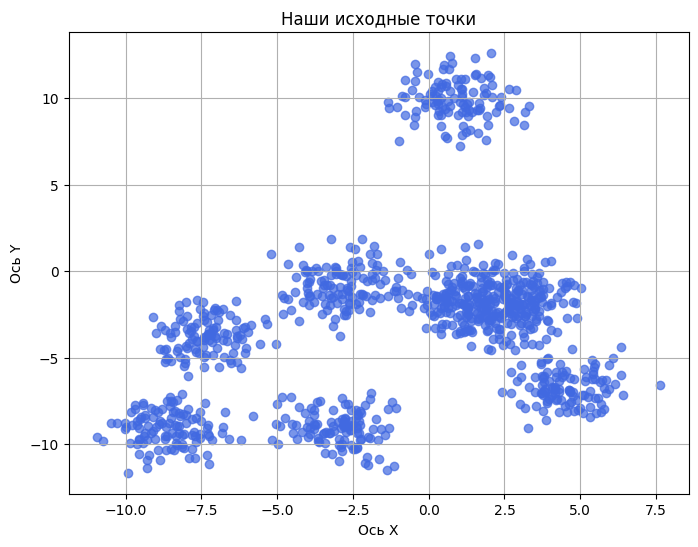

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(dataset[0], dataset[1], alpha=0.7, color='royalblue')
plt.title('Наши исходные точки')
plt.xlabel('Ось X')
plt.ylabel('Ось Y')
plt.grid(True)
plt.show()

Что мы видим на графике:

Точки лежат кучками. Если посчитать пальцем, то видно примерно 6 отдельных групп. Давайте попробуем запустить метод KMeans на 6 кластеров и посмотрим, как он их поделит.

Шаг 3: Кластеризация через KMeans

Создаем модель KMeans и просим ее поделить данные на 6 групп. Пишем random_state=42, чтобы при перезапуске графики не менялись.

In [11]:
kmeans_model = KMeans(n_clusters=6, random_state=42)
kmeans_labels = kmeans_model.fit_predict(dataset)

print("Центры получившихся кластеров:")
print(kmeans_model.cluster_centers_)

Центры получившихся кластеров:
[[ 2.16323462 -1.78106105]
 [-5.80073422 -9.09199275]
 [ 0.88668959  9.89326761]
 [ 4.53912946 -6.7042824 ]
 [-7.34772326 -3.75382477]
 [-2.75194144 -0.86386753]]


Рисуем результат KMeans

Теперь раскрасим наши точки в разные цвета в зависимости от того, в какую группу их закинул алгоритм.

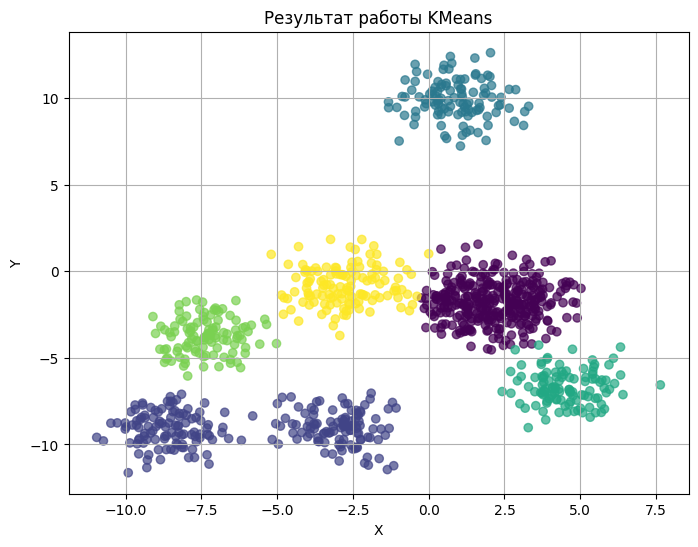

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(dataset[0], dataset[1], c=kmeans_labels, cmap='viridis', alpha=0.7)
plt.title('Результат работы KMeans')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.show()

Шаг 4: Пробуем метод DBSCAN для улучшения

Метод KMeans работает нормально, но у него есть минус - он сует каждую точку в какой-то кластер, даже если она лежит очень далеко от остальных и является просто шумом.

Давайте попробуем метод DBSCAN. Он сам находит плотные места. Зададим радиус поиска eps=1.0 и минимальное число точек рядом min_samples=5. Посмотрим, сколько групп он найдет.

In [13]:
dbscan_model = DBSCAN(eps=1.0, min_samples=5)
dbscan_labels = dbscan_model.fit_predict(dataset)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f'Алгоритм DBSCAN нашёл кластеров: {n_clusters}')
print(f'Количество шумовых точек (выбросов): {n_noise}')

Алгоритм DBSCAN нашёл кластеров: 4
Количество шумовых точек (выбросов): 5


Рисуем результат DBSCAN

Построим график для DBSCAN. Точки, которые алгоритм посчитал лишним шумом, будут помечены фиолетовым цветом с меткой -1.

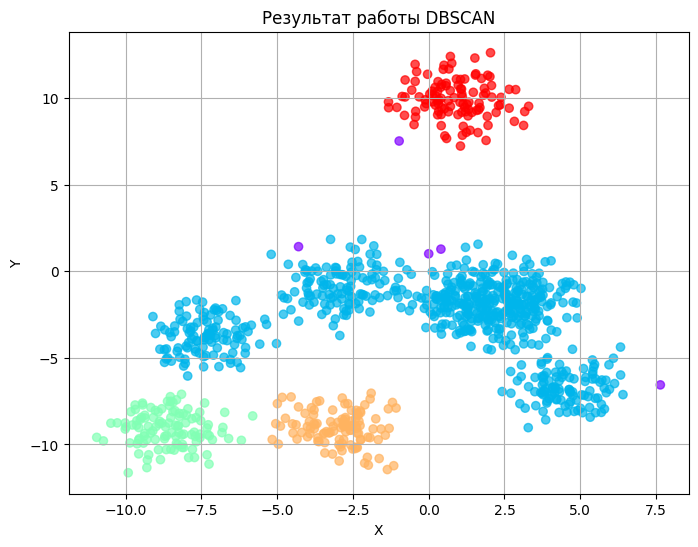

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(dataset[0], dataset[1], c=dbscan_labels, cmap='rainbow', alpha=0.7)
plt.title('Результат работы DBSCAN')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True)
plt.show()

Вывод по лабораторной работе

Я проанализировал наши данные из файла lab2-08.xlsx двумя способами:

1. KMeans справился очень хорошо, потому что наши кучки точек круглые и ровные. Поделил все ровно на 6 частей.
2. DBSCAN тоже показал хороший результат. Он сам нашел плотные группы и откинул несколько одиночных точек как шум. Это удобно, так как не надо заранее угадывать число групп.

Оба метода рабочие, но KMeans визуально поделил области даже чуть более аккуратно.